### Problem 5 : Membership Inference - can an outsider tell that Carol was in the training data ?

⏱️ ~35 min · 🧭 Stage 2 (Neural networks: the problem), rung 4 · 📄 `resources/papers/04-evaluation-and-privacy/` (Shokri 2017, Carlini 2022)

> 🔗 **Building on Problem 4 :** a network memorises atypical people, and because there is no single "right" network,
> forgetting can only be proven by **behaviour**. In Problems 1-4 we measured behaviour from the inside, with access to
> the training data. Now flip the point of view.

Imagine you are an **outsider** who can only query the model - send an input, get back probabilities - and you hold a
handful of digits that might or might not have been in the training set. Can you tell which ones were ?

That is a **membership inference attack (MIA)**. It matters twice over :

1. **As a threat :** if an attacker can tell that your medical record was used to train a hospital's model, the model
   is leaking private information - regardless of whether it ever prints your record.
2. **As an auditor's tool :** if, *after* unlearning, the attack can no longer tell Carol's digits from digits that were
   never in the training set, we have behavioural evidence that she is forgotten. Every audit from Problem 11 onwards
   is built on this.

**TASK :** Build a membership inference attack, run it on every model from Problems 1-4, then run it again *after*
unlearning to see the leak close.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from mul import lab, train, methods, classical, audit, viz
viz.style()

L = lab.make_lab("carol")
print(L)

Lab('carol': |D|=1257, |D_f|=40, |D_r|=1217, |test|=540)


#### The attacker's idea in one picture

> 🟢 **In plain words :** a model is usually *more confident* on examples it was trained on - it has seen the answer
> before. So the attacker asks the model about a digit, looks at how *surprised* the model is by the correct answer (the
> **loss**), and guesses : "low surprise → it was in training".

> 🔴 **For practitioners :** this is the loss-threshold attack (Yeom et al. 2018), the simplest member of the family
> Shokri et al. (2017) introduced with shadow models. Its strength is reported as **AUC** (0.5 = coin flip, 1.0 = always
> right) and, more importantly, **TPR at low FPR** - how many members you can flag *confidently* (Carlini et al. 2022).

The fair test always compares members against **non-members from the same distribution** - otherwise the attack just
learns "thick vs thin strokes". So :

- members = Carol's 40 thick-marker digits (in training)
- non-members = 80 unseen thick-marker digits (never in training)

#### Step 1 : Train - the network from Problem 4

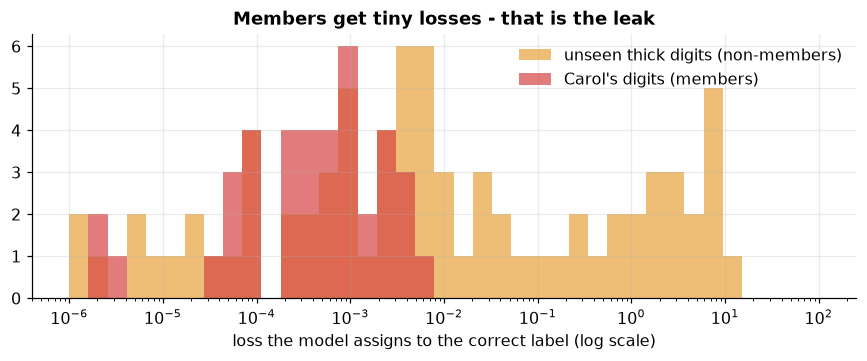

In [2]:
# Step 1: the original network (trained WITH Carol)
original = train.fit(lab.model_fn, L.X_train, L.y_train, seed=0, **lab.FIT)

l_carol = train.per_example_loss(original, L.Xf, L.yf)
l_unseen = train.per_example_loss(original, L.X_like_forget, L.y_like_forget)

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(-6, 2, 40)
ax.hist(l_unseen, bins=bins, color=viz.ACCENT, alpha=0.7, label="unseen thick digits (non-members)")
ax.hist(l_carol, bins=bins, color=viz.FORGET, alpha=0.7, label="Carol's digits (members)")
ax.set_xscale("log"); ax.set_xlabel("loss the model assigns to the correct label (log scale)"); ax.legend()
ax.set_title("Members get tiny losses - that is the leak"); plt.tight_layout(); plt.show()

#### Step 2 : Show the issue - attack every model from Problems 1-4

One attack, six models. For each, we compute the loss on members and non-members and score how well "low loss =
member" separates them.

model                     AUC  TPR @ 5% FPR
Naive Bayes (P1)         0.53          5.5%
k-NN, k=5 (P1)           0.59          8.2%
Logistic reg. (P2)       0.59          2.5%
RBF SVM (P3)             0.66         15.0%
Random forest (P3)       0.96         62.5%
Neural network (P4)      0.71          2.5%


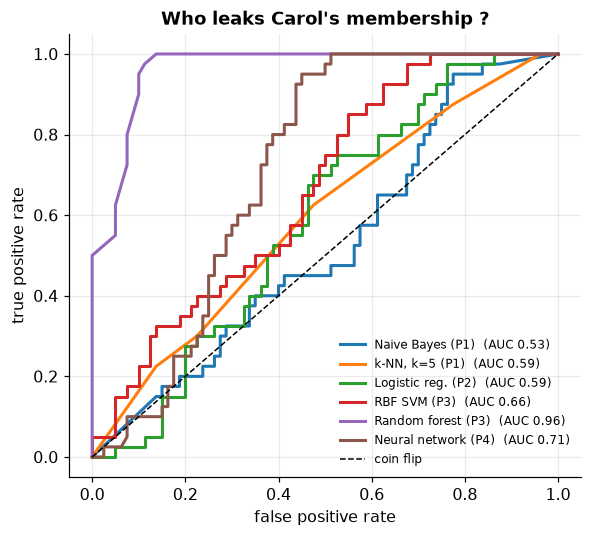

In [3]:
# Step 2: the same loss-threshold attack against every model we have built so far
models = {
    "Naive Bayes (P1)": classical.GaussianNB(1e-2).fit(L.X_train, L.y_train),
    "k-NN, k=5 (P1)": classical.KNN(5).fit(L.X_train, L.y_train),
    "Logistic reg. (P2)": classical.SoftmaxNewton(1.0).fit(L.X_train, L.y_train),
    "RBF SVM (P3)": classical.ScoredSVC(kernel="rbf", C=10, gamma="scale").fit(L.X_train, L.y_train),
    "Random forest (P3)": classical.BaggedForest(50, seed=0).fit(L.X_train, L.y_train),
    "Neural network (P4)": original,
}

def proba(m, X):
    return train.predict_proba(m, X) if hasattr(m, "params") else m.predict_proba(X)

attack = {}
for name, m in models.items():
    l_in = audit.proba_loss(proba(m, L.Xf), L.yf)
    l_out = audit.proba_loss(proba(m, L.X_like_forget), L.y_like_forget)
    attack[name] = audit.mia_from_losses(l_in, l_out)

print(f"{'model':22s}{'AUC':>7s}{'TPR @ 5% FPR':>14s}")
for name, r in attack.items():
    print(f"{name:22s}{r['auc']:7.2f}{r['tpr@5%fpr']:14.1%}")

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, r in attack.items():
    ax.plot(r["fpr"], r["tpr"], lw=2, label=f"{name}  (AUC {r['auc']:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="coin flip")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Who leaks Carol's membership ?"); plt.tight_layout(); plt.show()

Compare this table with the **memorisation gap** table of Problem 4. Broadly, they tell the same story from two
sides : the forest, the SVM and the network - flexible models that memorised Carol - **leak** her membership, while
Naive Bayes, which did not memorise her, is a coin flip.

The match is not perfect, and that is a lesson too. Logistic regression memorised her (Problem 4) yet barely leaks to
*this* attack, and the network's AUC (≈ 0.7) understates how strongly it memorised her. A single global loss threshold
is a **blunt instrument** : it cannot tell a digit that is *naturally* easy from one that is easy *because it was
trained on*. Keep that in mind - we fix it with a sharper attack below.

> ⚠️ **What about typical users?** Run the same attack on random training digits vs random test digits :

In [4]:
# Step 2b: typical members vs typical non-members (random train rows vs test rows)
rng = np.random.default_rng(0)
mem_idx = rng.choice(L.retain_idx, 300, replace=False)
non_idx = rng.choice(len(L.X_test), 300, replace=False)
r_typ = audit.loss_mia(original, L.X_train[mem_idx], L.y_train[mem_idx], L.X_test[non_idx], L.y_test[non_idx])
print(f"network, typical train vs test digits : AUC {r_typ['auc']:.2f}, TPR@5%FPR {r_typ['tpr@5%fpr']:.1%}")

network, typical train vs test digits : AUC 0.53, TPR@5%FPR 4.3%


Barely better than chance. Typical digits are *learned*, not *memorised* (Problem 4), so they hardly leak. Privacy risk -
and therefore the work of unlearning - is concentrated on unusual data. Averaged over a whole dataset, MIAs look weak;
**aimed at the right people, they are strong.** This is why Carlini et al. insist on per-example, low-FPR evaluation.

#### A stronger attack : per-example likelihood ratios (LiRA)

The loss threshold treats every digit the same. But some digits are *naturally* easy (a clean "1") and some naturally
hard. LiRA (Carlini et al. 2022) asks a sharper question **for each example separately** :

> *"How does a model that **trained on** this digit usually score it, how does a model that **didn't** usually score it,
> and which of the two does the target model look like?"*

To answer, the attacker trains **shadow models** - some with the digit (IN), some without (OUT) - and fits a bell curve
to each. Networks train in 0.3 s here, so we can afford 8 of each.

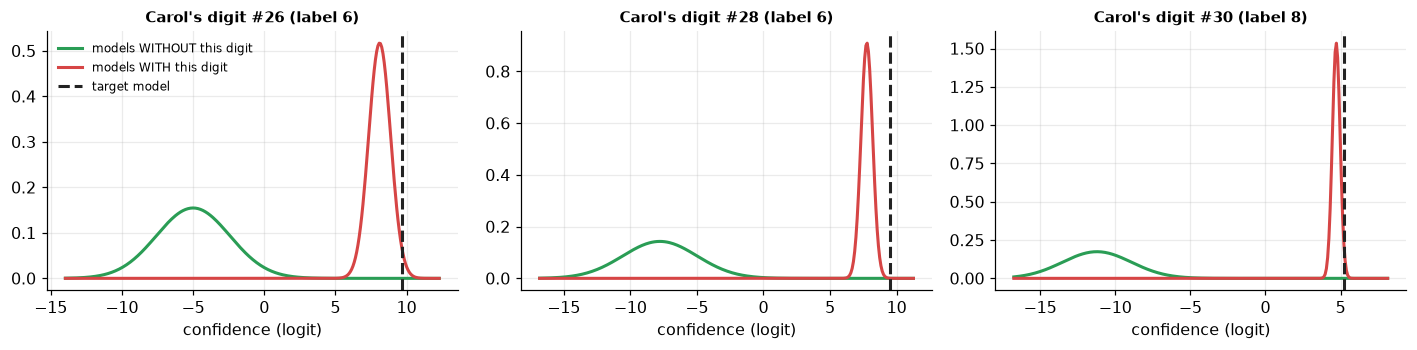

In [5]:
# Shadow models: IN = trained on all of D (includes Carol), OUT = trained on D_r (no Carol)
IN = [train.fit(lab.model_fn, L.X_train, L.y_train, seed=s, **lab.FIT) for s in range(1, 9)]
OUT = [train.fit(lab.model_fn, L.Xr, L.yr, seed=s, **lab.FIT) for s in range(11, 19)]

def phi(m, X, y):                                   # the statistic LiRA models: logit of the true-class probability
    p = np.clip(train.predict_proba(m, X)[np.arange(len(y)), y], 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

phi_in = np.stack([phi(m, L.Xf, L.yf) for m in IN])
phi_out = np.stack([phi(m, L.Xf, L.yf) for m in OUT])
phi_target = phi(original, L.Xf, L.yf)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
from scipy.stats import norm
for ax, i in zip(axes, np.argsort(phi_in.mean(0) - phi_out.mean(0))[-3:]):
    grid = np.linspace(min(phi_in[:, i].min(), phi_out[:, i].min()) - 3, max(phi_in[:, i].max(), phi_out[:, i].max()) + 3, 300)
    ax.plot(grid, norm.pdf(grid, phi_out[:, i].mean(), phi_out[:, i].std() + 1e-3), color=viz.RETRAIN, lw=2, label="models WITHOUT this digit")
    ax.plot(grid, norm.pdf(grid, phi_in[:, i].mean(), phi_in[:, i].std() + 1e-3), color=viz.FORGET, lw=2, label="models WITH this digit")
    ax.axvline(phi_target[i], color=viz.INK, lw=2, ls="--", label="target model")
    ax.set_title(f"Carol's digit #{i} (label {L.yf[i]})", fontsize=10); ax.set_xlabel("confidence (logit)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

For each of Carol's digits we now have two bell curves, and the target model's confidence lands squarely in the red
"trained on it" curve. `audit.ulira` turns this into a single number : **the fraction of D_f the test judges "still a
member"**. First we calibrate it - a fresh model *with* Carol must score high, a fresh model *without* her must score low :

In [6]:
# Calibration: held-out shadow models with known membership
ref_in, ref_out = IN[1:], OUT[1:]
print(f"held-out model trained WITH Carol    -> U-LiRA member-rate {audit.ulira(IN[0], L.Xf, L.yf, ref_in, ref_out):.2f}  (should be high)")
print(f"held-out model trained WITHOUT Carol -> U-LiRA member-rate {audit.ulira(OUT[0], L.Xf, L.yf, ref_in, ref_out):.2f}  (should be low)")

held-out model trained WITH Carol    -> U-LiRA member-rate 0.97  (should be high)
held-out model trained WITHOUT Carol -> U-LiRA member-rate 0.05  (should be low)


The test separates the two cleanly. That is a working **forgetting detector**.

#### Step 3 : Untrain

Use the exact unlearning methods we already know: retrain the network, and the exact classical methods from Problems 1-3.

In [7]:
# Step 3: exact unlearning for every model
unlearned = {
    "Naive Bayes (P1)": classical.GaussianNB(1e-2).fit(L.X_train, L.y_train).unlearn(L.Xf, L.yf),
    "k-NN, k=5 (P1)": classical.KNN(5).fit(L.X_train, L.y_train).unlearn(L.forget_idx),
    "Logistic reg. (P2)": classical.SoftmaxNewton(1.0).fit(L.X_train, L.y_train).unlearn_newton(L.Xr, L.yr, steps=3),
    "RBF SVM (P3)": classical.ScoredSVC(kernel="rbf", C=10, gamma="scale").fit(L.Xr, L.yr),
    "Random forest (P3)": classical.BaggedForest(50, seed=0).fit(L.Xr, L.yr),
    "Neural network (P4)": train.fit(lab.model_fn, L.Xr, L.yr, seed=0, **lab.FIT),
}

#### Step 4 : Show the result - attack again, before vs after

model                   AUC before  AUC after
Naive Bayes (P1)              0.53       0.40
k-NN, k=5 (P1)                0.59       0.46
Logistic reg. (P2)            0.59       0.47
RBF SVM (P3)                  0.66       0.58
Random forest (P3)            0.96       0.47
Neural network (P4)           0.71       0.48


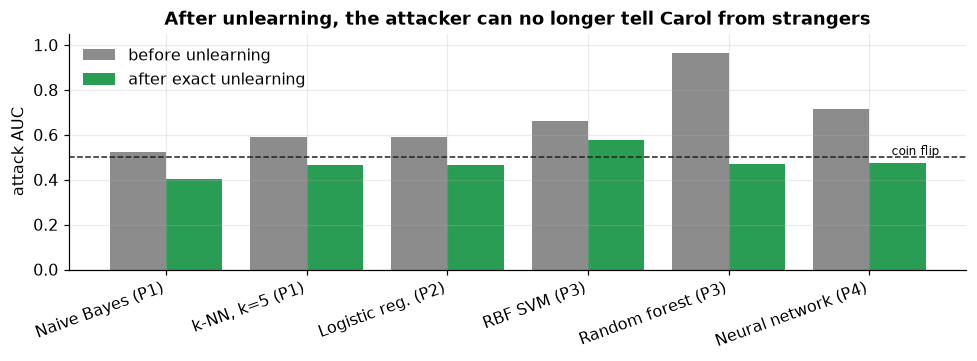

In [8]:
# Step 4: the same attack, after unlearning
after = {}
for name, m in unlearned.items():
    after[name] = audit.mia_from_losses(audit.proba_loss(proba(m, L.Xf), L.yf),
                                        audit.proba_loss(proba(m, L.X_like_forget), L.y_like_forget))

print(f"{'model':22s}{'AUC before':>12s}{'AUC after':>11s}")
for name in attack:
    print(f"{name:22s}{attack[name]['auc']:12.2f}{after[name]['auc']:11.2f}")

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(attack))
ax.bar(x - 0.2, [attack[n]["auc"] for n in attack], 0.4, color=viz.ORIGINAL, label="before unlearning")
ax.bar(x + 0.2, [after[n]["auc"] for n in attack], 0.4, color=viz.RETRAIN, label="after exact unlearning")
ax.axhline(0.5, color=viz.INK, ls="--", lw=1); ax.text(len(x) - 0.5, 0.51, "coin flip", fontsize=8, ha="right")
ax.set_xticks(x); ax.set_xticklabels(attack.keys(), rotation=20, ha="right"); ax.set_ylabel("attack AUC"); ax.set_ylim(0, 1.05)
ax.legend(loc="upper left"); ax.set_title("After unlearning, the attacker can no longer tell Carol from strangers"); plt.tight_layout(); plt.show()

#### Step 5 : Prove it - the per-example test on the network

In [9]:
retrained = unlearned["Neural network (P4)"]
print(f"U-LiRA member-rate  original : {audit.ulira(original, L.Xf, L.yf, ref_in, ref_out):.2f}")
print(f"U-LiRA member-rate  retrained: {audit.ulira(retrained, L.Xf, L.yf, ref_in, ref_out):.2f}")

U-LiRA member-rate  original : 0.95
U-LiRA member-rate  retrained: 0.05


✅ Notice the contrast with the blunt attack : on the *same* network, the loss threshold only reached AUC ≈ 0.7, but the
per-example test flags ~95% of Carol's digits. Before unlearning, the per-example test flags almost all of Carol's digits as members. After retraining, it flags
almost none - **the retrained model looks exactly like a model that never met her**, from the attacker's point of view.

> 🔴 **For practitioners :** three cautions that will matter later.
> 1. The shadow models must use the **same training recipe** as the target (architecture, epochs, data size). Problem 11
>    shows the audit giving a wrong verdict when the recipe differs.
> 2. AUC near 0.5 after unlearning does not mean *no* information remains - only that *this* attack cannot find it.
>    Stronger attacks exist (Hayes et al. 2024, in `resources/`), which is why we combine several tests.
> 3. An AUC far **below** 0.5 is also a red flag : it means the forgotten data is treated *worse* than strangers - the
>    "Streisand effect" you will meet in Problems 9-11.

----
#### OUTCOME :

| Question | Answer |
|---|---|
| Can an outsider detect Carol's membership in the original network? | **Yes** - the blunt loss attack only reaches AUC ≈ 0.7, but the per-example U-LiRA test flags ~95% of her digits |
| Can they detect a *typical* user? | Barely - typical data is learned, not memorised |
| Does the leak track Problem 4's memorisation gap? | **Broadly** - the flexible models leak most; a blunt attack under-reads some of them |
| After exact unlearning? | Loss attack falls to ≈ 0.5 for every model; U-LiRA drops from ~0.95 to ~0.05 |

We now own a **forgetting detector**. Every method from here on - exact or approximate - will be judged by it.

#### Key Takeaways :

- **Membership inference** turns memorisation into a measurable privacy leak.
- Always compare members against non-members **from the same distribution**, and report **TPR at low FPR**, not just AUC.
- **Per-example** tests (LiRA / U-LiRA) with shadow models are far stronger than a global loss threshold.
- After exact unlearning, the attack can no longer tell Carol from strangers - that is the behavioural proof.

#### TASK :
1. Run Step 2 on `lab.make_lab("class")` (forget the digit 3). What does the attack see when an entire *class* is
   members vs non-members ? Why is this case different?
2. Shrink the number of shadow models from 8 to 2. How unstable does U-LiRA become? How many would you want in a
   real audit?
3. Train the network with `weight_decay=1e-3` and re-run the attack. Does regularisation reduce the leak?
4. Shokri et al. train an *attack classifier* on shadow-model outputs instead of a fixed threshold. Read Section 4 of
   the paper in `resources/papers/04-evaluation-and-privacy/` and explain one advantage and one cost.

#### ❓ Open question → Problem 6
Our gold standard so far has been "**the** retrained model". But Problem 4 showed two networks trained on identical
data land in different places, and we just used *eight* of them as shadow models. So **what exactly is the target an
unlearning method must hit, how wide is it, and how much does it cost to compute?**